In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
from scipy.integrate import solve_ivp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel as C
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import random
import torch
import math
import torch.nn.functional as F

In [2]:
# Fix the seed

np.random.seed(42)
random.seed(42)

In [3]:


# ===================== User Settings =====================

Mr = 10.0 # robot mass
Tsim = 20.0 # simulation time in [s] #it was 60s
Ts = 0.05 # smapling time in [s], original 0.05 ms
num_samples = 10000 # number of samples in paramter space: 220
train_fraction = 0.80
peak_metric = 'max'  # 'max' or 'maxabs'



param_names = ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']

# Parameter ranges used for sampling

lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])




In [4]:
print(len(param_names))
print(lb.shape)
print(ub.shape)

9
(9,)
(9,)


In [5]:
# sampling the parameters

sampler = qmc.LatinHypercube(d=len(lb), seed=42) # this creates the sampler of dimension d
sample = sampler.random(n=num_samples) #this actually sample randomly within 0,1
X = qmc.scale(sample, lb, ub) # this scale the 0,1 results to our values

In [6]:
print(X.shape)
#print(sample) # this hould be 0 and 1 and in between
print(X) # our values

(10000, 9)
[[5.75900762e+02 2.28654950e+02 6.81142726e+01 ... 5.73156720e+00
  1.50012139e-01 4.37017438e-01]
 [4.95518931e+03 6.21178309e+02 1.13146591e+01 ... 3.72154093e+00
  1.27584454e-01 4.62498724e-01]
 [1.90524446e+03 1.76030048e+03 5.47501772e+01 ... 5.70775513e+00
  1.82108054e-01 4.91550666e-01]
 ...
 [1.72710990e+03 7.79065077e+02 5.83335447e+01 ... 4.54603437e+00
  1.98454172e-01 3.29124661e-01]
 [4.01012907e+03 3.05959248e+03 3.66423178e+01 ... 9.32660502e+00
  1.60852352e-01 4.76033476e-01]
 [2.27158968e+03 1.78239621e+03 4.86504995e+01 ... 6.77262189e+00
  1.14400092e-01 4.88396058e-01]]


In [7]:
# To simulate the system we need:
# - a function that describes the dynamic, "system dynamics"
# - the solver for the dynamical system, "simulate_peak_joint_position"
def chirp_signal(t, f0, f1, Tsim, A):
    """Generates a linear chirp signal."""
    k = (f1 - f0) / Tsim
    phi = 2 * np.pi * (f0 * t + 0.5 * k * t**2)
    return A * np.cos(phi)

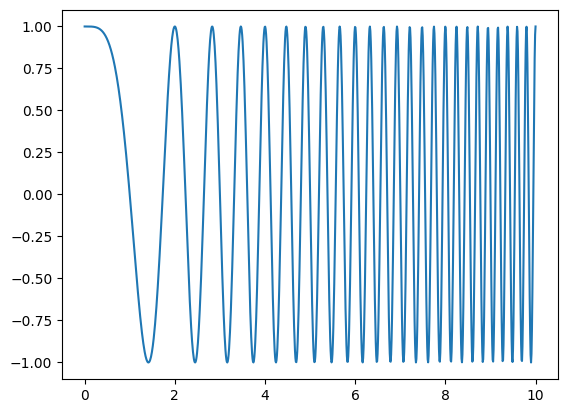

In [8]:
t_try = np.linspace(0,10,1000)
Chirp  =  chirp_signal(t_try,0,5,10,1)

Chirp.shape

plt.figure()
plt.plot(t_try,Chirp)
plt.show()

In [9]:
#chekcing what dict() does
p = dict(zip(param_names, X[150,:])) # create the dictionary
p

{'Kb': np.float64(3765.300572226375),
 'Kr': np.float64(1619.5695187394883),
 'Mb': np.float64(28.80744042578884),
 'hb': np.float64(0.1114739240676318),
 'hr': np.float64(0.47561256657436657),
 'f0': np.float64(0.008765446269348028),
 'f1': np.float64(8.888035679789365),
 'A_sin': np.float64(0.10646536324285319),
 'x_r_start': np.float64(0.3668661974646084)}

In [10]:
def system_dynamics(t, state, p, Mr):
    """Two-mass spring-damper system ODE."""
    xb, v_xb, xr, v_xr = state # state vector organised as [xb, v_xb, xr, v_xr]

    # xr is relative to the base

    # Extract params: WATCH OUT "p" is defined after as a dictionary

    Kb, Kr, Mb, hb, hr = p['Kb'], p['Kr'], p['Mb'], p['hb'], p['hr']
    A_sin, f0, f1 = p['A_sin'], p['f0'], p['f1']
    xr_start = p['x_r_start']

    # Active robot command (chirp position): that is compute the chirp signal
    x_cmd = xr_start + chirp_signal(t, f0, f1, Tsim, A_sin) # watch out for the sign

    cb = 2 * hb * Mb * np.sqrt(Kb / Mb)
    cr = 2 * hr * Mr * np.sqrt(Kr / Mr)

    # Equations of motion
    # Note: Assuming robot is controlled to follow x_cmd relative to base

    # For a surrogate model, we simulate the coupled ODE:
    a_b = (-Kr*x_cmd+Kr*xr+cr*v_xr-cb*v_xb-Kb*xb)/Mb

    # Simplified robot tracking dynamics
    a_r = (-Kr*xr-cr*v_xr+Kr*x_cmd)/Mr-a_b
    # it returns the left end side of the equation

    return [v_xb, a_b, v_xr, a_r]

In [11]:
def simulate_peak_joint_position(params_vec):

    # INPUT: "params_vec", it's the vector of parameters (1,9)

    p = dict(zip(param_names, params_vec)) # create the dictionary
    t_eval = np.arange(0, Tsim, Ts) # this is useful to state which points to take during the integration algorithm
    y0 = [0, 0, p['x_r_start'], 0] # initial condition of the state

    sol = solve_ivp(system_dynamics, [0, Tsim], y0, t_eval=t_eval, args=(p, Mr), method='RK45')


    # Output y = xb + xr
    # RECALL we organized the state as [xb, v_xb, xr, v_xr]
    # xb is sol.y[0], xr is sol.y[2]
    y_signal = sol.y[0] + sol.y[2] # this is the whole time history

    # we take just the max of the time history

    if peak_metric == 'maxabs':
        return np.max(np.abs(y_signal)), y_signal

    return np.max(y_signal), y_signal, sol.y[0], sol.y[2]

In [12]:
# simulate for 1 set of parameters

max_disp, y_signal, xb, xr = simulate_peak_joint_position(X[0,:])
y_signal = np.array(y_signal)
y_signal.shape
print(xb.shape, xr.shape)
xb = xb.reshape(1,-1)
xr = xr.reshape(1,-1)
y_riga_1200 = np.concatenate([xb, xr], axis=1)
print(y_riga_1200.shape)



(400,) (400,)
(1, 800)


In [13]:
# simulate for ALL the parameters we sampled

Y_MAT = []
Y_max = []
dof_mat = []

for i in range(len(X)):
    max_sig, y_signalv1,xb,xr = simulate_peak_joint_position(X[i,:])
    xb = xb.reshape(1,-1)
    xr = xr.reshape(1,-1)
    conc_sol = np.concatenate([xb, xr], axis=1)
    conc_sol_np = np.array(conc_sol)
    Y_MAT.append(y_signalv1)
    Y_max.append(max_sig)
    dof_mat.append(conc_sol_np) # ==============================================

print(np.array(Y_MAT).shape)
print(np.array(Y_max).shape)
dof_mat = np.vstack(dof_mat)
print(np.array(dof_mat).shape)

Y_MAT = np.vstack(Y_MAT)
Y_max = np.array(Y_max) # also peaks are stored in an array

print(Y_MAT.shape)
print(Y_max.shape)

nc = Y_MAT.shape[1] # number of time steps in the simulation

(10000, 400)
(10000,)
(10000, 800)
(10000, 400)
(10000,)


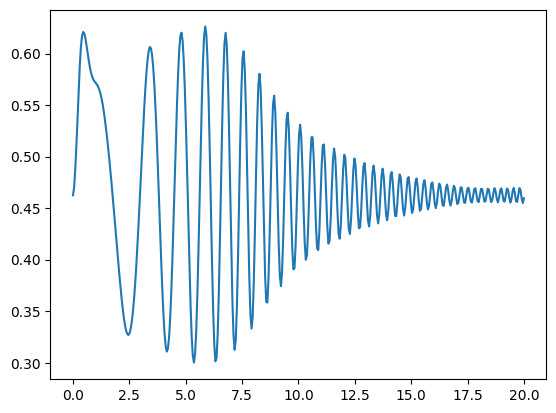

In [14]:
# visualization of some trajectories

t_plot = np.linspace(0,Tsim, np.size(Y_MAT,1))


plt.figure()
plt.plot(t_plot,Y_MAT[1,:])
plt.show()

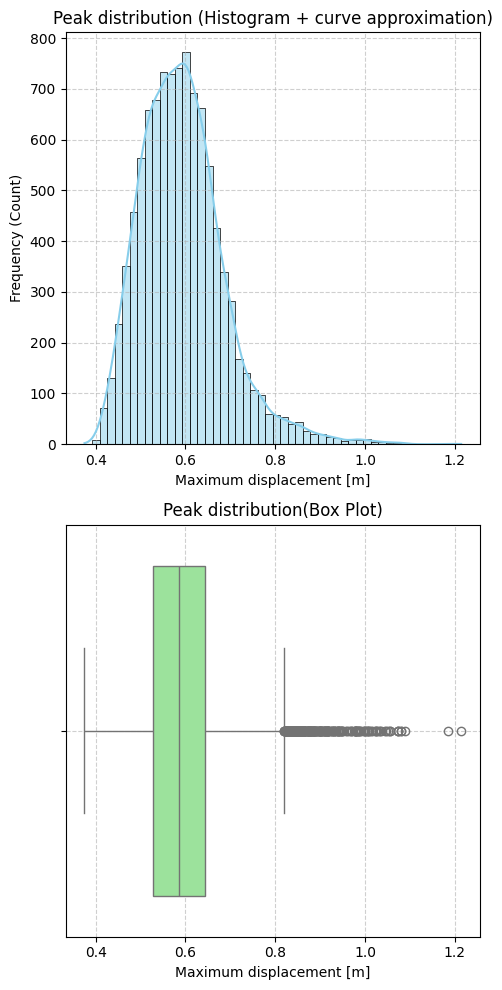

In [15]:
# PLOT DISTRIBUTION OF THE PEAKS

import seaborn as sns # Opzionale, ma rende i grafici molto più moderni

# Assicuriamoci che Y_max sia un array unidimensionale piatto
peaks = Y_max.flatten()

# Creiamo una figura con due grafici affiancati
fig, axes = plt.subplots(2, 1, figsize=(5, 10))

# 1. ISTOGRAMMA con stima della densità (KDE)
# Mostra la "forma" della distribuzione: se è a campana, asimmetrica o multimodale
sns.histplot(peaks, kde=True, ax=axes[0], color='skyblue', bins=50)
axes[0].set_title('Peak distribution (Histogram + curve approximation)')
axes[0].set_xlabel('Maximum displacement [m]')
axes[0].set_ylabel('Frequency (Count)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. BOX PLOT (Grafico a scatola e baffi)
# Evidenzia la mediana, i quartili e la presenza di eventuali valori anomali (outlier)
sns.boxplot(x=peaks, ax=axes[1], color='lightgreen')
axes[1].set_title('Peak distribution(Box Plot)')
axes[1].set_xlabel('Maximum displacement [m]')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### DATASET SPLIT

In [16]:
# split the data into training and val and testing sets
X_train, X_test_1stcut = train_test_split(X, test_size=0.3, random_state=42)
X_test, X_val = train_test_split(X_test_1stcut, test_size=0.5, random_state=42)

print(X_train.shape, X_test.shape, X_val.shape)

Y_max_train, Y_max_test_1stcut = train_test_split(Y_max, test_size=0.3, random_state=42)
Y_max_test, Y_max_val = train_test_split(Y_max_test_1stcut, test_size=0.5, random_state=42)

print(Y_max_train.shape, Y_max_test.shape, Y_max_val.shape)


(7000, 9) (1500, 9) (1500, 9)
(7000,) (1500,) (1500,)


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# scale everything

scaler_X = MinMaxScaler()
scaler_Y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
Y_train_scaled = scaler_Y.fit_transform(Y_max_train.reshape(-1,1))

X_val_scaled = scaler_X.transform(X_val)
Y_val_scaled = scaler_Y.transform(Y_max_val.reshape(-1,1))

X_test_scaled = scaler_X.transform(X_test)
Y_test_scaled = scaler_Y.transform(Y_max_test.reshape(-1,1))


In [18]:
X_train_scaled

array([[0.88877178, 0.81195649, 0.09473859, ..., 0.27686787, 0.07907665,
        0.11033328],
       [0.98822757, 0.7706414 , 0.94160011, ..., 0.49384836, 0.66715653,
        0.24495689],
       [0.60702587, 0.60460194, 0.78637628, ..., 0.59150166, 0.61041676,
        0.82026844],
       ...,
       [0.12742919, 0.07784678, 0.16877781, ..., 0.00659295, 0.79855028,
        0.48346662],
       [0.77699596, 0.61892421, 0.55980876, ..., 0.33834254, 0.15723049,
        0.53711229],
       [0.65098249, 0.71794504, 0.80476979, ..., 0.58488752, 0.46446568,
        0.87460113]], shape=(7000, 9))

In [19]:
# pass to tensor

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32) # to make it (N,1) instead of (N,)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val_scaled, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test_scaled, dtype=torch.float32)



In [20]:
Y_train_tensor.shape

torch.Size([7000, 1])

In [21]:

from torch.utils.data import TensorDataset, DataLoader

# create the datalaoder

# group everything for BATCH TRAINING
train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)


train_data = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_data   = DataLoader(dataset=val_dataset,   batch_size=64, shuffle=False)
test_data  = DataLoader(dataset=test_dataset,  batch_size=64, shuffle=False)

In [22]:
#check
print("Train  INPUT dataset shape:",X_train_tensor.shape)
print("Train OUTPUT dataset shape:",Y_train_tensor.shape)

Train  INPUT dataset shape: torch.Size([7000, 9])
Train OUTPUT dataset shape: torch.Size([7000, 1])


### NN architecture

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import trange, tqdm

In [24]:
# actually get the dimension of the input and output

n_input = X_train.shape[1]
n_output = Y_max_train.reshape(-1,1).shape[1]
n_hidden1 = 256
n_hidden2 = 128

In [25]:

class NN_get_peak(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=n_hidden1,n_hidden2=n_hidden2):
        super(NN_get_peak, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)  # 3 input features, 64 hidden units
        self.fc2 = nn.Linear(n_hidden1, n_hidden2) # 64 hidden units, 32 hidden units
        self.fc3 = nn.Linear(n_hidden2, n_output)  # 32 hidden units, 1 output
        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [26]:
# MODEL SETTINGS

model = NN_get_peak(n_input,n_output)
loss_criterion = nn.MSELoss()
eta = 1e-3 # Learning Rate
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 100
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=20)

In [27]:
def train_model(model, train_data, loss_criterion, optimizer, loss_logger, epoch_idx):
  model.train() # Set the model to training mode
  total_loss = 0
  for batch_idx, (data,target) in enumerate(tqdm(train_data, desc="Training", leave=False)):
    pred_output = model(data)
    loss = loss_criterion(pred_output, target)
    optimizer.zero_grad() # Clears all gradients; prevent gradient accumulation
    loss.backward() # Computes gradient of loss wrt model parameters
    optimizer.step() # Updates model paraments using computed gradients
    #loss_logger.append(loss.item()) # Logs the loss; convenient if batch_size = dataset_size
    # .item() - Converts tensor into a python number
    total_loss += loss.item() # Track/accumulate the loss

  avg_loss = total_loss / len(train_data) # Compute the average loss
  loss_logger.append(avg_loss) # Store the loss

  #print(f"Epoch: {epoch_idx} | Loss: {avg_loss:.4f}")


  return model, optimizer, loss_logger

In [28]:
def validate_model(model, val_data, loss_criterion, val_loss_logger):
    model.eval() # Set to evaluation mode
    total_loss = 0
    with torch.no_grad():
        for data, target in val_data:
            pred_output = model(data)
            loss = loss_criterion(pred_output, target)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_data)
    val_loss_logger.append(avg_loss)
    return val_loss_logger

In [29]:
def test_model(model, test_data, loss_criterion, loss_logger):
  total_loss = 0
  with torch.no_grad():
    for batch_idx, (data,target) in enumerate(tqdm(test_data, desc="Testing", leave=False)):
      pred_output = model(data)
      loss = loss_criterion(pred_output, target)
      #loss_logger.append(loss.item())
      total_loss += loss.item()

    avg_loss = total_loss / len(test_data)
    loss_logger.append(avg_loss)

    return loss_logger, pred_output

In [30]:
train_loss = []
val_loss = []
test_loss = []

for i in trange(n_epochs, desc="Epoch", leave=False):
    # Train
    model, optimizer, train_loss = train_model(model, train_data, loss_criterion, optimizer, train_loss, epoch_idx=i)

    # Validate (Check performance on unseen "practice" data)
    val_loss = validate_model(model, val_data, loss_criterion, val_loss)
    scheduler.step(val_loss[-1])

    # Optional: Print progress
    # print(f"Epoch {i}: Train Loss: {train_loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f}")


# 3. Test (Only once, after all epochs are finished)
test_loss, pred_test_output = test_model(model, test_data, loss_criterion, test_loss)



Epoch:   0%|          | 0/100 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

... (92 outputs left out)

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Training:   0%|          | 0/110 [00:00<?, ?it/s]

Testing:   0%|          | 0/24 [00:00<?, ?it/s]

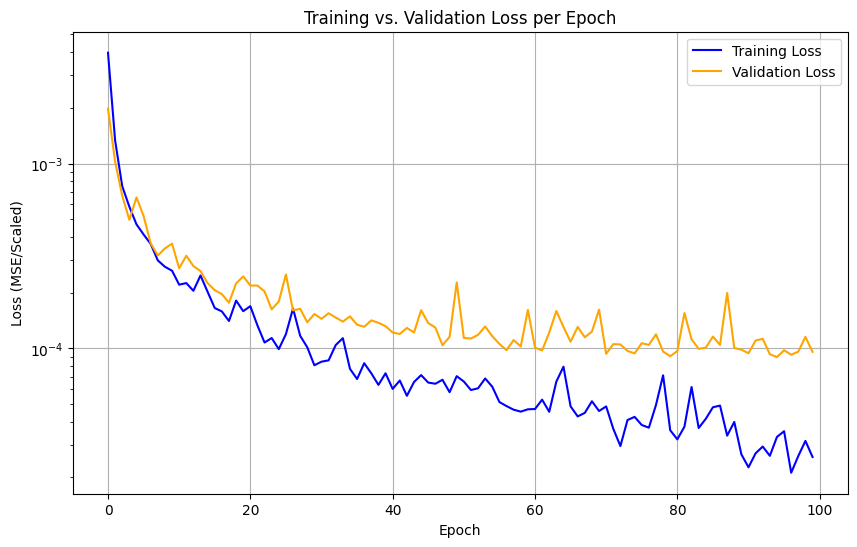

Final Training Loss: 0.000026
Final Validation Loss: 0.000095
Final Test Loss: 0.0001


In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plotting both on the same axes
plt.semilogy(train_loss, label='Training Loss', color='blue')
plt.semilogy(val_loss, label='Validation Loss', color='orange')

# Training and Validation Plot
plt.title('Training vs. Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/Scaled)')
plt.legend()
plt.grid(True)
plt.show()


print(f"Final Training Loss: {train_loss[-1]:.6f}")
print(f"Final Validation Loss: {val_loss[-1]:.6f}")
print(f"Final Test Loss: {test_loss[-1]:.4f}")

In [32]:
# Assess final results (solution)

def assess_results(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        y_hat = model(X)

        # Prediction and plotting
        #plt.figure(figsize = (4, 4))
        #plt.plot(y_hat.numpy(), 'r-', label='Predicted output')
        #plt.plot(y.numpy(), 'b-', label='True output')
        #plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        #plt.legend()
        #plt.show()

        # Prediction and plotting
        plt.figure(figsize = (2, 2))
        plt.scatter(y_hat.numpy(), y.numpy())
        plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)  # Line for perfect predictions
        plt.xlabel('Predicted output')
        plt.ylabel('True output')
        plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        plt.legend()
        plt.grid(True)
        plt.show()

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)


        # R2 calculation
        total_variance = torch.var(y)
        residual_variance = torch.mean((y_hat - y) ** 2)
        R2 = 1 - residual_variance / total_variance

    return rmse, R2


In [33]:
def assess_results_real(model, X, y_scaled, scaler_Y, data_type):
    """
    Come assess_results, ma il parity plot e le metriche sono calcolati
    in scala reale (unità fisiche), non nello spazio normalizzato [0,1].
    """
    model.eval()
    with torch.no_grad():
        y_hat_scaled = model(X)

        # Riporto predizioni e target in scala reale
        y_hat_real = scaler_Y.inverse_transform(y_hat_scaled.numpy())
        y_real = scaler_Y.inverse_transform(y_scaled.numpy())

        # Parity plot in scala reale
        plt.figure(figsize=(4, 4))
        plt.scatter(y_hat_real, y_real)
        plt.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()], 'k--', lw=2)
        plt.xlabel('Predicted output (real scale)')
        plt.ylabel('True output (real scale)')
        plt.title(f'Predicted vs Estimated output: {data_type} dataset (real scale)')
        plt.grid(True)
        plt.show()

        # RMSE in scala reale
        mse = np.mean((y_hat_real - y_real) ** 2)
        rmse = np.sqrt(mse)

        # R2 in scala reale
        total_variance = np.var(y_real)
        residual_variance = np.mean((y_hat_real - y_real) ** 2)
        R2 = 1 - residual_variance / total_variance

    print(f'{data_type.capitalize()} results (real scale)')
    print(f"rmse = {rmse:.4f}. R2 = {R2:.3f}")

    return rmse, R2

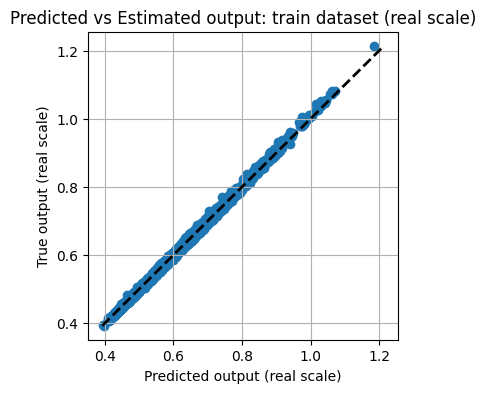

Train results (real scale)
rmse = 0.0037. R2 = 0.998


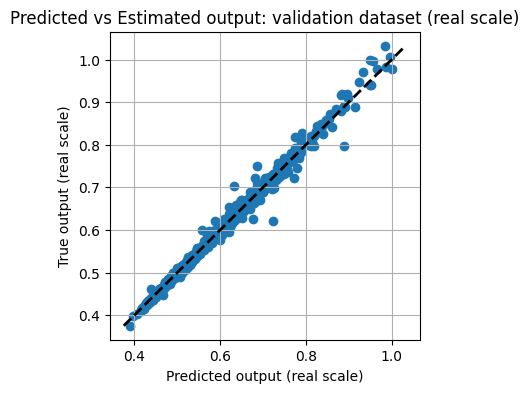

Validation results (real scale)
rmse = 0.0081. R2 = 0.992


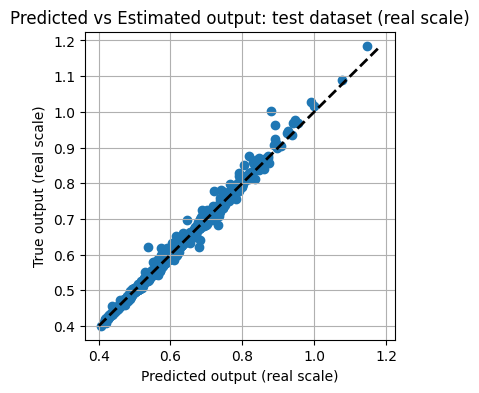

Test results (real scale)
rmse = 0.0085. R2 = 0.992


In [34]:
# Assess results in training (real scale)
rmse_train_real, R2_train_real = assess_results_real(model, X_train_tensor, Y_train_tensor.view(-1,1), scaler_Y, data_type='train')

# Assess results in validation (real scale)
rmse_val_real, R2_val_real = assess_results_real(model, X_val_tensor, Y_val_tensor.view(-1,1), scaler_Y, data_type='validation')

# Assess results in test (real scale)
rmse_test_real, R2_test_real = assess_results_real(model, X_test_tensor, Y_test_tensor.view(-1,1), scaler_Y, data_type='test')

C:\Users\utente1\AppData\Local\Temp\ipykernel_35940\2598935822.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


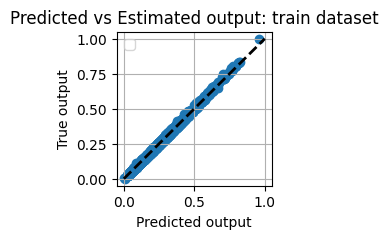

Training results
rmse = 0.0045. R2 = 0.998


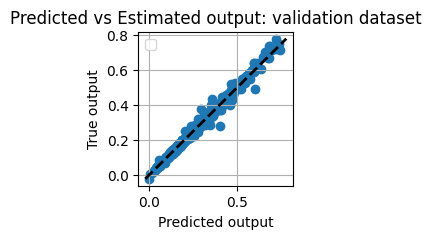

Validation results
rmse = 0.0099. R2 = 0.992


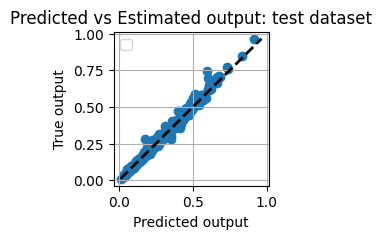

Test results
rmse = 0.0103. R2 = 0.992


In [35]:
# Assess results in training
rmse_train, R2_train = assess_results(model, X_train_tensor, Y_train_tensor.view(-1,1), data_type = 'train')
print('Training results')
print(f"rmse = {rmse_train:.4f}. R2 = {R2_train:.3f}")

# Assess results in validation
rmse_val, R2_val = assess_results(model, X_val_tensor, Y_val_tensor.view(-1,1), data_type = 'validation')
print('Validation results')
print(f"rmse = {rmse_val:.4f}. R2 = {R2_val:.3f}")

# Assess results in test
rmse_test, R2_test = assess_results(model, X_test_tensor, Y_test_tensor.view(-1,1), data_type = 'test')
print('Test results')
print(f"rmse = {rmse_test:.4f}. R2 = {R2_test:.3f}")

### INFERENCE ON TEST SET

In [36]:
X_test.shape

(1500, 9)

In [37]:
# TRUE
MAX_TEST = []
for i in range(X_test_tensor.shape[0]):
    # Get the input parameters
    input_params = X_test[i,:] # WATCH OUT THESE VALUES ARE NOT SCALED (CORRECT)
    # solve the EOM
    max_disp, y_signal, xb,xr = simulate_peak_joint_position(input_params)
    # STORE the RESULTS
    MAX_TEST.append(max_disp)

In [38]:
print(np.array(MAX_TEST).shape)
print(np.array(MAX_TEST))
print(np.max(np.array(MAX_TEST)))

(1500,)
[0.47763308 0.59214638 0.71871411 ... 0.69774431 0.58512183 0.63418845]
1.1853263434752415


In [39]:
with torch.no_grad():
    # PREDICTION
    Y_test_tensor = model(X_test_tensor)

# SCALE BACK
Y_test_tensor_unscaled = scaler_Y.inverse_transform(Y_test_tensor.detach().numpy())


In [40]:
print(Y_test_tensor_unscaled.shape)
print(np.max(Y_test_tensor_unscaled))

(1500, 1)
1.1465906


In [41]:
# COMPARISON ON TEXT VISUALIZATION

# pass to NUMPY
Y_test_unscaled_np = np.array(Y_test_tensor_unscaled)
MAX_TEST_np = np.array(MAX_TEST).reshape(-1,1)

print('Comparison of true vs predicted values on the test set:')
print("="*50)

# Intestazione delle colonne
print(f"{'True Values':<20} | {'Predicted Values':<20}")
print("-" * 45)

# Appiattiamo i vettori per ciclarli in parallelo con zip
true_flat = np.array(MAX_TEST).flatten()
pred_flat = Y_test_unscaled_np.flatten()

# Stampiamo riga per riga
for t_val, p_val in zip(true_flat, pred_flat):
    # .4f serve se vuoi limitare i decimali a 4 cifre, puoi toglierlo se sono interi
    print(f"{t_val:<20.4f} | {p_val:<20.4f}")

Comparison of true vs predicted values on the test set:
True Values          | Predicted Values    
---------------------------------------------
0.4776               | 0.4780              
0.5921               | 0.5943              
0.7187               | 0.7254              
0.6872               | 0.6890              
0.6717               | 0.6704              
0.5734               | 0.5758              
0.5854               | 0.5897              
0.5512               | 0.5553              
0.6221               | 0.5372              
0.5040               | 0.4956              
0.6176               | 0.6182              
0.5751               | 0.5784              
0.5850               | 0.5874              
0.7102               | 0.7007              
0.7258               | 0.7291              
0.5093               | 0.5078              
0.4891               | 0.4928              
0.5785               | 0.5862              
0.4598               | 0.4586              
0.4288            

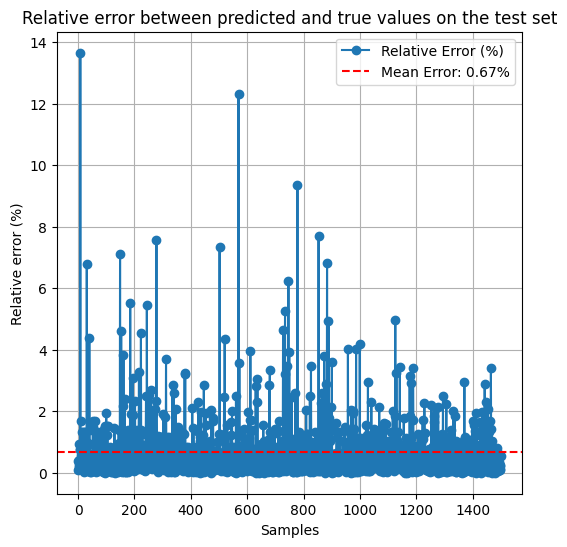

In [42]:
# ERROR PLOT

error = np.abs(Y_test_unscaled_np.flatten() - np.array(MAX_TEST).flatten())
error_rel = error / np.array(MAX_TEST).flatten() * 100
mn_err = np.mean(error_rel)
plt.figure(figsize=(6, 6))
plt.plot(error_rel, '-o', label='Relative Error (%)')
plt.axhline(mn_err, color='r', linestyle='--', label=f'Mean Error: {mn_err:.2f}%')
plt.legend()
plt.xlabel('Samples')
plt.ylabel('Relative error (%)')
plt.grid(True)
plt.title('Relative error between predicted and true values on the test set')
plt.show()  




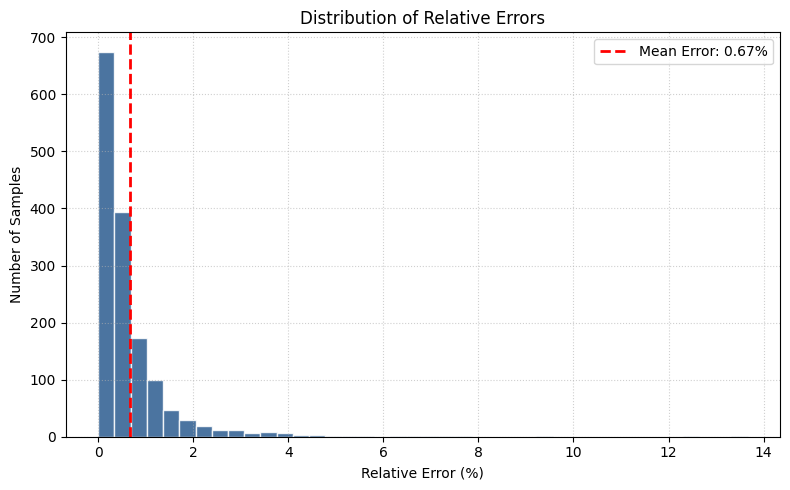

In [43]:
plt.figure(figsize=(8, 5))

# Istogramma con densità/frequenza
plt.hist(
    error_rel,
    bins=40,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.85,
    density=False,
)

# Linea per la media
plt.axvline(
    mn_err,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean Error: {mn_err:.2f}%",
)

plt.xlabel("Relative Error (%)")
plt.ylabel("Number of Samples")
plt.title("Distribution of Relative Errors")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
# ERROR ANALYSIS

std_err = np.std(error_rel)

thr_st = std_err + mn_err
thr_nd = 2*std_err + mn_err
thr_rd = 3*std_err + mn_err

#find in error_rel the indexes of the samples that are above the thresholds
idx_st = np.where(error_rel > thr_st)[0]
idx_nd = np.where(error_rel > thr_nd)[0]
idx_rd = np.where(error_rel > thr_rd)[0]

print('These are the indexes for 1 sigma distance:', idx_st)
print('These are the indexes for 2 sigma distance:', idx_nd)
print('These are the indexes for 3 sigma distance:', idx_rd)


# extract back the parameters for the samples that are above the thresholds
X_test_bad = X_test[idx_st]
X_test_bad_nd = X_test[idx_nd]
X_test_bad_rd = X_test[idx_rd]



These are the indexes for 1 sigma distance: [   8    9   31   40   53   60  100  149  153  159  161  165  185  189
  194  195  202  216  223  241  244  250  259  266  274  276  278  302
  307  312  335  339  346  378  380  405  426  435  446  453  473  478
  479  502  518  520  544  546  560  569  572  604  610  611  612  630
  633  636  678  680  714  727  733  734  740  746  749  758  771  778
  809  822  826  853  861  864  873  878  883  888  889  898  900  957
  969  975  976  986  999 1028 1040 1068 1116 1124 1125 1129 1141 1155
 1176 1178 1182 1188 1189 1222 1228 1253 1264 1268 1277 1294 1306 1331
 1335 1370 1399 1412 1434 1442 1445 1453 1462 1464]
These are the indexes for 2 sigma distance: [   8   31   40  149  153  161  185  194  216  223  244  259  278  312
  335  378  380  446  502  520  569  572  611  630  636  678  680  727
  733  734  740  746  749  778  826  853  873  878  883  888  900  957
  986  999 1028 1125 1129 1141 1176 1182 1188 1370 1442 1464]
These are the ind

In [45]:
import pandas as pd

print('The worst parameters (above 3 sigma) are:')
print("="*60)

# Verifichiamo prima se ci sono effettivamente campioni oltre i 3 sigma
if X_test_bad_rd.shape[0] > 0:
    
    # 1. Trasponiamo la matrice (.T) in modo che i parametri vadano sulle righe
    # e i singoli campioni vadano sulle colonne
    matrix_transposed = X_test_bad_rd.T
    
    # 2. Creiamo i nomi per le colonne: "Sample 1", "Sample 2", ...
    column_names = [f"Sample {i+1}" for i in range(X_test_bad_rd.shape[0])]
    
    # 3. Costruiamo il DataFrame impostando param_names come righe (index)
    df_worst = pd.DataFrame(
        matrix_transposed, 
        index=param_names, 
        columns=column_names
    )
    
    # 4. Stampa pulita (il float_format limita i decimali a 4 cifre per non far sballare le colonne)
    print(df_worst.to_string(float_format=lambda x: f"{x:<10.4f}"))

else:
    print("Fortunatamente nessun campione supera la soglia dei 3 sigma!")

The worst parameters (above 3 sigma) are:
            Sample 1   Sample 2   Sample 3   Sample 4   Sample 5   Sample 6   Sample 7   Sample 8   Sample 9  Sample 10  Sample 11  Sample 12  Sample 13  Sample 14  Sample 15  Sample 16  Sample 17  Sample 18  Sample 19  Sample 20  Sample 21  Sample 22  Sample 23  Sample 24  Sample 25  Sample 26  Sample 27  Sample 28
Kb        143.6036   3653.2185  1620.9077  2707.2314  3749.7376  1747.3405  2843.9794  2585.4482  4892.5411  994.7816   2914.1579  4959.8643  3661.2134  4555.1900  608.0935   449.3428   4861.6154  3563.8200  1686.9420  1465.0758  4445.6198  1035.1167  4184.9583  4730.4489  853.9178   3912.6206  259.2658   3535.8076 
Kr        681.9539   203.5567   4632.3873  242.2863   490.0205   355.5368   359.7825   3536.6759  1306.7193  705.9266   379.2623   583.9497   235.6105   423.3477   1000.5012  624.3486   634.1258   299.6146   4051.1646  4354.6401  653.7278   173.2873   1498.8542  498.9116   3322.6993  4762.8242  871.4091   526.3396  
Mb  

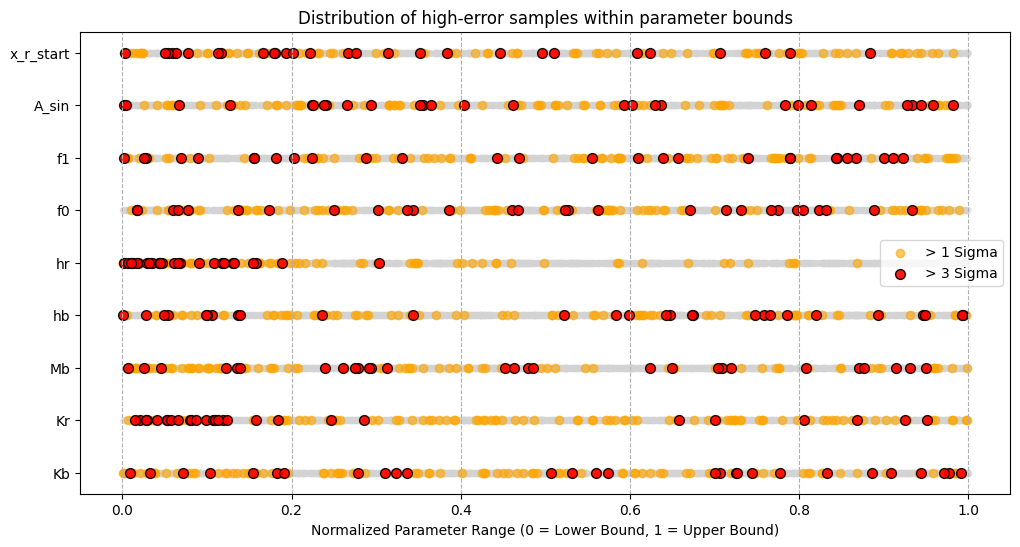

In [46]:
# Creiamo un DataFrame con tutti i parametri del test set
df_test_all = pd.DataFrame(X_test, columns=param_names)

# Aggiungiamo la colonna dell'errore relativo per fare filtri rapidi
df_test_all['Error_Rel'] = error_rel

plt.figure(figsize=(12, 6))

# Creiamo una rappresentazione visiva per ogni parametro
for i, name in enumerate(param_names):
    # Min e Max usati durante il campionamento (lb e ub globali)
    p_min = lb[i]
    p_max = ub[i]
    
    # Normalizziamo i valori correnti tra 0 e 1 per poterli confrontare nello stesso grafico
    vals_all = (df_test_all[name] - p_min) / (p_max - p_min)
    vals_bad_1s = (X_test_bad[:, i] - p_min) / (p_max - p_min)
    vals_bad_3s = (X_test_bad_rd[:, i] - p_min) / (p_max - p_min) if X_test_bad_rd.shape[0] > 0 else []

    # Disegniamo la distribuzione di base (grigio chiaro) e i campioni critici sopra
    y_pos = np.ones_like(vals_all) * i
    plt.scatter(vals_all, y_pos, color='lightgray', alpha=0.3, s=20)
    plt.scatter(vals_bad_1s, np.ones_like(vals_bad_1s) * i, color='orange', alpha=0.6, label='> 1 Sigma' if i==0 else "")
    if len(vals_bad_3s) > 0:
        plt.scatter(vals_bad_3s, np.ones_like(vals_bad_3s) * i, color='red', alpha=0.9, s=50, edgecolors='black', label='> 3 Sigma' if i==0 else "")

plt.yticks(range(len(param_names)), param_names)
plt.xlabel('Normalized Parameter Range (0 = Lower Bound, 1 = Upper Bound)')
plt.title('Distribution of high-error samples within parameter bounds')
plt.legend()
plt.grid(True, axis='x', linestyle='--')
plt.show()

In [47]:
# Calcoliamo la correlazione di Pearson e di Spearman (per relazioni non lineari)
correlations_pearson = df_test_all[param_names].corrwith(df_test_all['Error_Rel'], method='pearson')
correlations_spearman = df_test_all[param_names].corrwith(df_test_all['Error_Rel'], method='spearman')

df_corr = pd.DataFrame({
    'Pearson (Linear)': correlations_pearson,
    'Spearman (Rank/Non-linear)': correlations_spearman
})

print("Correlation between physical parameters and Relative Error:")
print("="*65)
print(df_corr.round(3).to_string())
print("="*65)
print("Interpretation: Values close to 1 or -1 indicate that the parameter strongly drives the error.")

Correlation between physical parameters and Relative Error:
           Pearson (Linear)  Spearman (Rank/Non-linear)
Kb                   -0.031                      -0.038
Kr                   -0.078                      -0.021
Mb                   -0.104                      -0.119
hb                   -0.007                       0.007
hr                   -0.370                      -0.368
f0                   -0.022                       0.019
f1                   -0.018                      -0.025
A_sin                -0.012                      -0.070
x_r_start            -0.117                      -0.125
Interpretation: Values close to 1 or -1 indicate that the parameter strongly drives the error.


### CHECK OF LEARNING

## <span style="font-size: 75%;">Section 1: Case set and variation of parameters</span>


In [48]:


# Extarct causally the idx
random_idx = random.randint(0, X_test.shape[0] - 1)
print(f"Randomly selected test sample index: {random_idx}")
print("=" * 50)

# take the param vec for that sample
selected_parameters = X_test[random_idx, :]

# get a dataframe
df_sample = pd.DataFrame({
    'Parameter': param_names,
    'Value': selected_parameters
})

# print
print(df_sample.to_string(index=False, formatters={'Value': lambda x: f"{x:<12.4f}"}))
print("=" * 50)



Randomly selected test sample index: 1309
Parameter        Value
       Kb 369.9434    
       Kr 2286.5470   
       Mb 60.9255     
       hb 0.2739      
       hr 0.2799      
       f0 0.0084      
       f1 7.1597      
    A_sin 0.1947      
x_r_start 0.4047      


In [49]:
print(selected_parameters)
print(param_names)

[3.69943424e+02 2.28654702e+03 6.09254864e+01 2.73929630e-01
 2.79949967e-01 8.38911839e-03 7.15974958e+00 1.94699401e-01
 4.04701483e-01]
['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']


In [50]:
# VARY THE PARAMETERS: hb, hr, A_sin

# Recuperiamo i valori base direttamente dall'array NumPy usando gli indici corretti
hr_base    = selected_parameters[4] # hr è all'indice 4
hb_base    = selected_parameters[3] # hb è all'indice 3
A_sin_base = selected_parameters[7] # A_sin è all'indice 7

print(hr_base, hb_base, A_sin_base)

0.27994996735518407 0.273929629579888 0.194699400622234


In [51]:
# VARY THE PARAMETERS: hb, hr, A_sin


# perturbation of the parameters: recall the bounds are 0.1-0.3 for hb, 0.1-1.1 for hr, 0.1-0.2 for A_sin
hr_to_test = [0.68, hr_base,0.8,0.9]
#hb_to_test = [0.13, hb_base, 0.2, 0.25]
#A_sin_to_test = [0.1, A_sin_base, 0.15 ,0.18 ]

# create the small grid of parameters to test

X_test_grid = []
for i in range(len(hr_to_test)):
    selected_params_cp = selected_parameters.copy()
    selected_params_cp[4] = hr_to_test[i] # update hr
  #  selected_params_cp[3] = hb_to_test[i] # update hb
   # selected_params_cp[7] = A_sin_to_test[i] # update A_sin
    X_test_grid.append(selected_params_cp)


X_test_grid_final = np.column_stack(X_test_grid)

print("Final dimension matrix:", X_test_grid_final.shape)

print(X_test_grid_final)    

Final dimension matrix: (9, 4)
[[3.69943424e+02 3.69943424e+02 3.69943424e+02 3.69943424e+02]
 [2.28654702e+03 2.28654702e+03 2.28654702e+03 2.28654702e+03]
 [6.09254864e+01 6.09254864e+01 6.09254864e+01 6.09254864e+01]
 [2.73929630e-01 2.73929630e-01 2.73929630e-01 2.73929630e-01]
 [6.80000000e-01 2.79949967e-01 8.00000000e-01 9.00000000e-01]
 [8.38911839e-03 8.38911839e-03 8.38911839e-03 8.38911839e-03]
 [7.15974958e+00 7.15974958e+00 7.15974958e+00 7.15974958e+00]
 [1.94699401e-01 1.94699401e-01 1.94699401e-01 1.94699401e-01]
 [4.04701483e-01 4.04701483e-01 4.04701483e-01 4.04701483e-01]]


In [52]:
# TRUTH

GRID_MAX = []

for k in range(X_test_grid_final.shape[1]):
    # Get the input parameters
    input_params = X_test_grid_final[:, k] # WATCH OUT THESE VALUES ARE NOT SCALED (CORRECT)
    # solve the EOM
    max_disp, y_signal, xb,xr = simulate_peak_joint_position(input_params)
    # STORE the RESULTS
    GRID_MAX.append(max_disp)

print(np.array(GRID_MAX).shape)
print(GRID_MAX)

(4,)
[np.float64(0.5867804604978156), np.float64(0.685344776502963), np.float64(0.5866403879556075), np.float64(0.5860427287149524)]


In [53]:
# SCALE 

X_test_grid_scaled = scaler_X.transform(X_test_grid_final.reshape(-1,9))
Y_test_grid_scaled = scaler_Y.transform(np.array(GRID_MAX).reshape(-1,1))



In [54]:
# PASS TO TENSOR
X_test_grid_tensor = torch.tensor(X_test_grid_scaled, dtype=torch.float32)
Y_test_grid_tensor = torch.tensor(Y_test_grid_scaled, dtype=torch.float32)

In [55]:
# PREDICTION
with torch.no_grad():
    Y_test_grid_tensor_pred = model(X_test_grid_tensor)

# SCALE BACK
Y_test_grid_pred = scaler_Y.inverse_transform(Y_test_grid_tensor_pred.numpy())

In [56]:
# SHAPE CHECK
Y_test_grid_pred.shape
Y_test_grid_pred

array([[5.8908330e+03],
       [1.5093068e+00],
       [2.1548882e+01],
       [1.5879930e+00]], dtype=float32)

In [57]:
import pandas as pd
import numpy as np

# 1. Recuperiamo i valori predetti
pred_values = Y_test_grid_pred.flatten()

# 2. Convertiamo X_test_grid in un array NumPy prima di fare .T
X_test_grid_np = np.array(X_test_grid)

# 3. Ora creiamo il DataFrame usando la matrice trasposta
col_names = ['Test 1 (0.5x)', 'Test 2 (Base)', 'Test 3 (1.5x)', 'Test 4 (2.0x)']
df_results = pd.DataFrame(X_test_grid_np, columns=param_names, index=col_names)

# 4. Aggiungiamo la colonna della predizione
df_results['--> PREDICTED MAX'] = pred_values

# 5. Trasponiamo il DataFrame finale per rimetterlo in verticale
df_final = df_results.T

# 6. Stampa pulita
print("=" * 65)
print(" COMPARISON OF MODIFIED PARAMETERS AND MODEL PREDICTIONS")
print("=" * 65)
print(df_final.to_string(formatters={col: lambda x: f"{x:<14.4f}" for col in col_names}))
print("=" * 65)

 COMPARISON OF MODIFIED PARAMETERS AND MODEL PREDICTIONS
                   Test 1 (0.5x)  Test 2 (Base)  Test 3 (1.5x)  Test 4 (2.0x)
Kb                369.9434       369.9434       369.9434       369.9434      
Kr                2286.5470      2286.5470      2286.5470      2286.5470     
Mb                60.9255        60.9255        60.9255        60.9255       
hb                0.2739         0.2739         0.2739         0.2739        
hr                0.6800         0.2799         0.8000         0.9000        
f0                0.0084         0.0084         0.0084         0.0084        
f1                7.1597         7.1597         7.1597         7.1597        
A_sin             0.1947         0.1947         0.1947         0.1947        
x_r_start         0.4047         0.4047         0.4047         0.4047        
--> PREDICTED MAX 5890.8330      1.5093         21.5489        1.5880        


In [58]:
import numpy as np
import torch
import pandas as pd

# 1. Creiamo i parametri alternativi per hr (manteniamo 4 righe x 9 colonne)
hr_to_test = [0.68, hr_base, 0.8, 0.9]

X_test_grid = []
for i in range(len(hr_to_test)):
    selected_params_cp = selected_parameters.copy()
    selected_params_cp[4] = hr_to_test[i]  # Aggiorna hr
    X_test_grid.append(selected_params_cp)

# Convertiamo in array: shape nativa (4, 9) -> Perfetto per scaler_X!
X_test_grid_final = np.array(X_test_grid)
print("Dimensione corretta della matrice di input:", X_test_grid_final.shape) # Deve essere (4, 9)

# 2. RISOLUZIONE DEL SOLUTORE FISICO (VERITÀ)
GRID_MAX = []
for k in range(X_test_grid_final.shape[0]):  # Cicliamo sulle righe (4 campioni)
    input_params = X_test_grid_final[k, :]   # Estraiamo la riga k
    max_disp, y_signal, xb, xr = simulate_peak_joint_position(input_params)
    GRID_MAX.append(max_disp)

# 3. SCALING CORRETTO (Senza reshape distruttivi)
X_test_grid_scaled = scaler_X.transform(X_test_grid_final) 
GRID_MAX_np = np.array(GRID_MAX).reshape(-1, 1)

# 4. PASSAGGIO A TENSORI E PREDIZIONE
X_test_grid_tensor = torch.tensor(X_test_grid_scaled, dtype=torch.float32)

with torch.no_grad():
    Y_test_grid_tensor_pred = model(X_test_grid_tensor)

# 5. SCALE BACK DELL'OUTPUT PREDETTO
Y_test_grid_pred = scaler_Y.inverse_transform(Y_test_grid_tensor_pred.numpy()).flatten()

# 6. COSTRUZIONE DEL DATAFRAME DI CONFRONTO
col_names = ['Test 1 (hr=0.68)', 'Test 2 (Base)', 'Test 3 (hr=0.80)', 'Test 4 (hr=0.90)']

# Creiamo il DataFrame (4 righe dei test x 9 colonne dei parametri)
df_results = pd.DataFrame(X_test_grid_final, columns=param_names, index=col_names)

# Aggiungiamo le due colonne finali di analisi
df_results['--> TRUE MAX (Solver)'] = GRID_MAX_np
df_results['--> PREDICTED MAX (NN)'] = Y_test_grid_pred

# Trasponiamo per la visualizzazione verticale ordinata
df_final = df_results.T

# 7. STAMPA FINALE
print("=" * 75)
print("     COMPARISON OF MODIFIED PARAMETERS: TRUE VS PREDICTED")
print("=" * 75)
print(df_final.to_string(formatters={col: lambda x: f"{x:<18.4f}" for col in col_names}))
print("=" * 75)

Dimensione corretta della matrice di input: (4, 9)
     COMPARISON OF MODIFIED PARAMETERS: TRUE VS PREDICTED
                         Test 1 (hr=0.68)      Test 2 (Base)   Test 3 (hr=0.80)   Test 4 (hr=0.90)
Kb                     369.9434           369.9434           369.9434           369.9434          
Kr                     2286.5470          2286.5470          2286.5470          2286.5470         
Mb                     60.9255            60.9255            60.9255            60.9255           
hb                     0.2739             0.2739             0.2739             0.2739            
hr                     0.6800             0.2799             0.8000             0.9000            
f0                     0.0084             0.0084             0.0084             0.0084            
f1                     7.1597             7.1597             7.1597             7.1597            
A_sin                  0.1947             0.1947             0.1947             0.1947            


In [59]:
import numpy as np
import torch
import pandas as pd

# 1. Generiamo i valori di hr da 0.1 a 1.1 (es. 6 punti equispaziati)
hr_to_test = np.linspace(0.1, 1.1, 10)

X_test_grid = []
for i in range(len(hr_to_test)):
    selected_params_cp = selected_parameters.copy()
    selected_params_cp[4] = hr_to_test[i]  # Aggiorna hr all'indice 4
    X_test_grid.append(selected_params_cp)

# Convertiamo in array NumPy: dimensione nativa (6, 9)
X_test_grid_final = np.array(X_test_grid)
print("Dimensione della matrice di input:", X_test_grid_final.shape) # (6, 9)

# 2. RISOLUZIONE DEL SOLUTORE FISICO (VERITÀ)
GRID_MAX = []
for k in range(X_test_grid_final.shape[0]):  # Cicliamo sulle 6 righe
    input_params = X_test_grid_final[k, :]   # Estraiamo il vettore dei parametri fisici
    max_disp, y_signal, xb, xr = simulate_peak_joint_position(input_params)
    GRID_MAX.append(max_disp)

# 3. SCALING CORRETTO PER LA RETE
X_test_grid_scaled = scaler_X.transform(X_test_grid_final) 
GRID_MAX_np = np.array(GRID_MAX).reshape(-1, 1)

# 4. PASSAGGIO A TENSORI E PREDIZIONE
X_test_grid_tensor = torch.tensor(X_test_grid_scaled, dtype=torch.float32)

with torch.no_grad():
    Y_test_grid_tensor_pred = model(X_test_grid_tensor)

# 5. SCALE BACK DELL'OUTPUT PREDETTO
Y_test_grid_pred = scaler_Y.inverse_transform(Y_test_grid_tensor_pred.numpy()).flatten()

# 6. COSTRUZIONE DEL DATAFRAME DI CONFRONTO
# Creiamo etichette dinamiche per le colonne in base al valore reale di hr
col_names = [f'hr = {val:.2f}' for val in hr_to_test]

# Creiamo il DataFrame (6 righe dei test x 9 colonne dei parametri)
df_results = pd.DataFrame(X_test_grid_final, columns=param_names, index=col_names)

# Aggiungiamo le righe finali di analisi
df_results['--> TRUE MAX (Solver)'] = GRID_MAX_np
df_results['--> PREDICTED MAX (NN)'] = Y_test_grid_pred

# Trasponiamo per la visualizzazione verticale ordinata
df_final = df_results.T

# 7. STAMPA FINALE DELLA TABELLA
print("=" * 95)
print("       SENSITIVITY ANALYSIS OF HR (0.1 TO 1.1): SOLVER VS NEURAL NETWORK")
print("=" * 95)
print(df_final.to_string(formatters={col: lambda x: f"{x:<14.4f}" for col in col_names}))
print("=" * 95)

Dimensione della matrice di input: (10, 9)
       SENSITIVITY ANALYSIS OF HR (0.1 TO 1.1): SOLVER VS NEURAL NETWORK
                            hr = 0.10      hr = 0.21      hr = 0.32      hr = 0.43      hr = 0.54      hr = 0.66      hr = 0.77      hr = 0.88      hr = 0.99      hr = 1.10
Kb                     369.9434       369.9434       369.9434       369.9434       369.9434       369.9434       369.9434       369.9434       369.9434       369.9434      
Kr                     2286.5470      2286.5470      2286.5470      2286.5470      2286.5470      2286.5470      2286.5470      2286.5470      2286.5470      2286.5470     
Mb                     60.9255        60.9255        60.9255        60.9255        60.9255        60.9255        60.9255        60.9255        60.9255        60.9255       
hb                     0.2739         0.2739         0.2739         0.2739         0.2739         0.2739         0.2739         0.2739         0.2739         0.2739        
hr                 

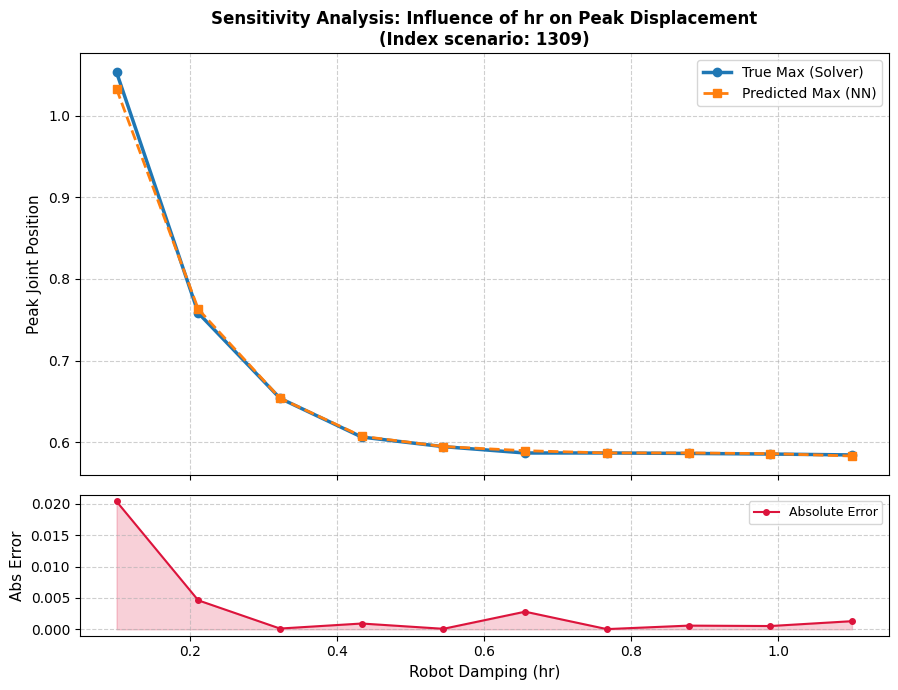

In [60]:
# PLOT

import matplotlib.pyplot as plt

# Creiamo una figura con due sotto-grafici (uno per i picchi e uno per l'errore)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1]})

# --- 1. GRAFICO DEI VALORI DI PICCO ---
# Curva del Solutore Fisico (Verità)
ax1.plot(hr_to_test, GRID_MAX, 'o-', color='#1f77b4', lw=2.5, ms=6, label='True Max (Solver)')
# Curva della Rete Neurale (Predizione)
ax1.plot(hr_to_test, Y_test_grid_pred, 's--', color='#ff7f0e', lw=2.0, ms=6, label='Predicted Max (NN)')

ax1.set_ylabel('Peak Joint Position', fontsize=11)
ax1.set_title(f'Sensitivity Analysis: Influence of hr on Peak Displacement\n(Index scenario: {random_idx})', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=10)

# --- 2. GRAFICO DELL'ERRORE ASSOLUTO ---
absolute_error = np.abs(GRID_MAX - Y_test_grid_pred)
ax2.fill_between(hr_to_test, absolute_error, color='crimson', alpha=0.2)
ax2.plot(hr_to_test, absolute_error, 'o-', color='crimson', lw=1.5, ms=4, label='Absolute Error')

ax2.set_xlabel('Robot Damping (hr)', fontsize=11)
ax2.set_ylabel('Abs Error', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=9, loc='upper right')

# Ottimizzazione dello spazio e visualizzazione
plt.tight_layout()
plt.show()

## <span style="font-size: 75%;">Section 2: Out of bounds</span>

It's to be expected a tremendous error if the NN is working out of its working bounds (u are violating the hp of the Universal approximation theorem). To solve this problem a PINN can be implemented

### Minimization routine

A simple minimization approach lead to a wrong result as a local minimum is encountered!

In [61]:
import numpy as np
import torch
from scipy.optimize import minimize

# L -BFGS-B 
# is a local minimizer! WATCH OUT FOR THE INITIALS POINTS AND BOUNS

def objective_function(x_parameters):
    # x_parameters viene passato da Scipy come array 1D fisico
    
    # a. Scaliamo l'input nel modo in cui la rete se lo aspetta
    x_scaled = scaler_X.transform(x_parameters.reshape(1, -1))
    tensor_in = torch.tensor(x_scaled, dtype=torch.float32)
    
    # b. Inferenza con la rete
    with torch.no_grad():
        pred_scaled = model(tensor_in)
        
    # c. De-scaliamo per ottenere il valore in metri (o unità reali)
    pred_real = scaler_Y.inverse_transform(pred_scaled.numpy())[0, 0]
    
    # Restituiamo il valore NEGATIVO per fare la massimizzazione
    return -pred_real

# 2. Definiamo i confini dello spazio (i tuoi lb e ub originari)
# Scipy accetta una lista di tuple (min, max) per ogni parametro
bounds = list(zip(lb, ub))

# 3. Scegliamo un punto di partenza casuale (es. il centro della griglia)
x0 = (np.array(lb) + np.array(ub)) / 2.0

# 4. Lanciamo l'ottimizzatore
print("Ricerca del massimo spostamento in corso...")
res = minimize(objective_function, x0, method='L-BFGS-B', bounds=bounds)

# 5. Estraiamo e stampiamo i risultati
best_physical_params = res.x
max_displacement = -res.fun

print("=" * 60)
print(f" MASSIMO SPOSTAMENTO TROVATO: {max_displacement:.4f}")
print("=" * 60)
print("Configurazione ottima dei parametri:")
for name, val in zip(param_names, best_physical_params):
    print(f" -> {name:<12}: {val:.4f}")
print("=" * 60)

Ricerca del massimo spostamento in corso...
 MASSIMO SPOSTAMENTO TROVATO: 0.5674
Configurazione ottima dei parametri:
 -> Kb          : 2550.0000
 -> Kr          : 2550.0000
 -> Mb          : 55.0000
 -> hb          : 0.2000
 -> hr          : 0.6000
 -> f0          : 0.0050
 -> f1          : 6.5000
 -> A_sin       : 0.1500
 -> x_r_start   : 0.4000


In [62]:
# MONTE CARLO
# Generiamo 500.000 combinazioni casuali uniformi in tutto lo spazio
n_samples = 500_000
X_random_search = np.random.uniform(lb, ub, size=(n_samples, len(lb)))

# Scaliamo ed eseguiamo l'inferenza in blocco sulla rete
X_rs_scaled = scaler_X.transform(X_random_search)
tensor_rs = torch.tensor(X_rs_scaled, dtype=torch.float32)

with torch.no_grad():
    preds_rs_scaled = model(tensor_rs)

preds_rs_real = scaler_Y.inverse_transform(preds_rs_scaled.numpy()).flatten()

# Troviamo il massimo valore assoluto visto dalla rete
best_idx = np.argmax(preds_rs_real)
print(f"Massimo assoluto predetto dalla rete su 500k punti: {preds_rs_real[best_idx]:.4f}")

Massimo assoluto predetto dalla rete su 500k punti: 1.1765


# FIX BASE PARAMETERS AND A TARGET

## Inverse Problem Formulation: Target-to-Parameter Mapping

Given a fixed base configuration $\boldsymbol{p}_{\text{base}} = \{M_b, h_b, K_b\} \in \mathcal{D}_{\text{base}}$, our goal is to solve the **Inverse Kinematic/Dynamic Problem**. 

Specifically, we want to construct a mapping $\mathcal{G}$ that receives a desired scalar peak joint response $y_{\text{target}} \in \mathbb{R}$ and maps it to a set of robot and excitation parameters $\boldsymbol{p}_{\text{robot}} \in \mathbb{R}^6$ capable of achieving that target displacement.

---

### 1. Domain and Parameter Partitioning fro DATASET generation

We partition the full 9-dimensional parameter space $\mathcal{D} \subset \mathbb{R}^9$ into fixed base parameters and tunable system parameters:

$$\boldsymbol{p} = [\boldsymbol{p}_{\text{base}}, \; \boldsymbol{p}_{\text{robot}}]^T \in \mathbb{R}^9$$

Where:
* **Fixed Base Vector:** $\boldsymbol{p}_{\text{base}} = [M_b, \; h_b, \; K_b]^T \in \mathbb{R}^3$
* **Tunable Parameters Vector:** $\boldsymbol{p}_{\text{robot}} = [K_r, \; h_r, \; f_0, \; f_1, \; A_{\text{sin}}, \; x_{r,\text{start}}]^T \in \mathbb{R}^6$

---


#### Inverse Mapping ($\mathcal{G}$)
The inverse mapping seeks a parameter configuration $\boldsymbol{p}_{\text{robot}}$ for a specified scalar displacement target $y_{\text{target}}$:

$$\mathcal{G}_{\boldsymbol{p}_{\text{base}}}: \mathbb{R} \to \mathbb{R}^6$$

$$\boldsymbol{p}_{\text{robot}} = \mathcal{G}_{\boldsymbol{p}_{\text{base}}}(y_{\text{target}})$$



In [63]:
tensor_rs.shape
best_idx

np.int64(75736)

In [64]:
# Fix base parameters 

param_real_values = scaler_X.inverse_transform(X_rs_scaled)
print(param_real_values.shape)

param_found = param_real_values[best_idx]
print(param_found)


(500000, 9)
[2.60831548e+03 4.90122191e+03 9.81421962e+01 2.69046144e-01
 1.04179874e-01 7.48639639e-03 9.28983214e+00 1.99127322e-01
 4.59679017e-01]


In [65]:
print("="*60)
print("OPTIMAL PARAMETERS WHERE MAXIMUM IS: \n")
print("MAX  displacement is:", preds_rs_real[best_idx], "m")
for i in param_names:
    idx = param_names.index(i)
    print(f"{i:<12}: {param_found[idx]:.4f}")

OPTIMAL PARAMETERS WHERE MAXIMUM IS: 

MAX  displacement is: 1.1764746 m
Kb          : 2608.3155
Kr          : 4901.2219
Mb          : 98.1422
hb          : 0.2690
hr          : 0.1042
f0          : 0.0075
f1          : 9.2898
A_sin       : 0.1991
x_r_start   : 0.4597


In [66]:
param_found.shape

(9,)

In [67]:
# ODE CHECK

max_to_check, _, _,_ = simulate_peak_joint_position(param_found)
print(f"Maximum displacement from ODE solver for the found parameters: {max_to_check:.4f} m")

Maximum displacement from ODE solver for the found parameters: 1.1971 m


In [68]:
# Base values

Kb_set = param_found[0]
Mb_set = param_found[2]   # indice corretto
hb_set = param_found[3]


print("The base parrrameters are the following:")
print("="*50)
print("Base stiffness Kb:", Kb_set, "N/m")
print("Base adimensional damping hb:", hb_set)
print("Base mass Mb:", Mb_set, "kg")

# DATASET GENERATION FOR THE INVERSE PROBLEM

X_inverse = X.copy()      # anche qui: X_inverse = X crea solo un alias, non una copia!
X_inverse[:, 0] = Kb_set
X_inverse[:, 2] = Mb_set  # colonna corretta
X_inverse[:, 3] = hb_set

# check
print(X_inverse.shape)
print(X_inverse[:5, :]) 

The base parrrameters are the following:
Base stiffness Kb: 2608.3154848951754 N/m
Base adimensional damping hb: 0.2690461438410426
Base mass Mb: 98.1421961676916 kg
(10000, 9)
[[2.60831548e+03 2.28654950e+02 9.81421962e+01 2.69046144e-01
  6.98390582e-01 8.58135413e-03 5.73156720e+00 1.50012139e-01
  4.37017438e-01]
 [2.60831548e+03 6.21178309e+02 9.81421962e+01 2.69046144e-01
  4.81317724e-01 3.81899102e-03 3.72154093e+00 1.27584454e-01
  4.62498724e-01]
 [2.60831548e+03 1.76030048e+03 9.81421962e+01 2.69046144e-01
  6.09902930e-01 4.56401581e-03 5.70775513e+00 1.82108054e-01
  4.91550666e-01]
 [2.60831548e+03 3.50591440e+03 9.81421962e+01 2.69046144e-01
  1.56803249e-01 3.61516743e-03 9.49154068e+00 1.21885304e-01
  4.69276211e-01]
 [2.60831548e+03 2.21362690e+03 9.81421962e+01 2.69046144e-01
  9.97856285e-01 1.92077565e-03 6.09350981e+00 1.29616876e-01
  3.03263355e-01]]


In [69]:
# DATASET OUTPUT
'''
# simulate for ALL the parameters we sampled

Y_MAT_inv = []
Y_max_inv = []
dof_mat_inv = []

for i in range(len(X)):
    max_sig, y_signalv1,xb,xr = simulate_peak_joint_position(X_inverse[i,:])
    xb = xb.reshape(1,-1)
    xr = xr.reshape(1,-1)
    conc_sol = np.concatenate([xb, xr], axis=1)
    conc_sol_np = np.array(conc_sol)
    Y_MAT_inv.append(y_signalv1)
    Y_max_inv.append(max_sig)
    dof_mat_inv.append(conc_sol_np) # ==============================================

print(np.array(Y_MAT_inv).shape)
print(np.array(Y_max_inv).shape)
dof_mat_inv = np.vstack(dof_mat_inv)
print(np.array(dof_mat_inv).shape)

Y_MAT_inv = np.vstack(Y_MAT_inv)
Y_max_inv = np.array(Y_max_inv) # also peaks are stored in an array

print(Y_MAT_inv.shape)
print(Y_max_inv.shape)
'''


'\n# simulate for ALL the parameters we sampled\n\nY_MAT_inv = []\nY_max_inv = []\ndof_mat_inv = []\n\nfor i in range(len(X)):\n    max_sig, y_signalv1,xb,xr = simulate_peak_joint_position(X_inverse[i,:])\n    xb = xb.reshape(1,-1)\n    xr = xr.reshape(1,-1)\n    conc_sol = np.concatenate([xb, xr], axis=1)\n    conc_sol_np = np.array(conc_sol)\n    Y_MAT_inv.append(y_signalv1)\n    Y_max_inv.append(max_sig)\n    dof_mat_inv.append(conc_sol_np) # ==============================================\n\nprint(np.array(Y_MAT_inv).shape)\nprint(np.array(Y_max_inv).shape)\ndof_mat_inv = np.vstack(dof_mat_inv)\nprint(np.array(dof_mat_inv).shape)\n\nY_MAT_inv = np.vstack(Y_MAT_inv)\nY_max_inv = np.array(Y_max_inv) # also peaks are stored in an array\n\nprint(Y_MAT_inv.shape)\nprint(Y_max_inv.shape)\n'

### Algorithm: Input Inversion via Autograd (*Adjoint-Based Input Optimization*)

---

```text
================================================================================
INPUT:
  - f_θ          : Differentiable Surrogate Neural Network with frozen weights θ
  - p_base_bar   : Fixed base parameters vector (in R^3)
  - y_target     : Desired target response scalar value (in R)
  - lb, ub       : Lower and upper bounds for p_robot (in R^6)
  - η            : Optimizer learning rate
  - MaxIter      : Maximum number of iterations
  - ε            : Stopping threshold tolerance on the Loss

OUTPUT:
  - p_robot_star : Optimal robot parameter configuration (in R^6)

--------------------------------------------------------------------------------
INITIALIZATION:
  1. Freeze neural network parameters: θ_grad = False
  2. Choose initial point in normalized space:
     z_0 ∈ [0, 1]^6  (e.g., z_0 = [0.5, 0.5, 0.5, 0.5, 0.5, 0.5]^T)
  3. Enable gradient tracking for decision variables:
     z.requires_grad = True
  4. Map p_base_bar into normalized space z_base ∈ [0, 1]^3

--------------------------------------------------------------------------------
OPTIMIZATION LOOP (k = 0, 1, ..., MaxIter - 1):
  
  a. FULL INPUT RECONSTRUCTION:
     Map z_k to physical space: p_robot_k = lb + z_k ⊙ (ub - lb)
     Assemble full 9D normalized vector: X_k = [z_base, z_k]^T
     
  b. FORWARD PASS (Model Evaluation):
     y_pred_k = f_θ(X_k)
     
  c. COST FUNCTION EVALUATION:
     J_k = 0.5 * (y_pred_k - y_target)^2 + λ * R(p_robot_k)
     
  d. STOPPING CRITERION:
     IF J_k < ε THEN:
         BREAK LOOP
     END IF
     
  e. BACKWARD PASS (Automatic Differentiation):
     Compute gradient g_k = ∇_z J_k via Reverse-Mode Autograd
     
  f. STATE UPDATE (Descent Step):
     z_{k+1} = OPTIMIZER_STEP(z_k, g_k, η)   [e.g., via ADAM or L-BFGS]
     
  g. BOX CONSTRAINTS PROJECTION:
     z_{k+1} = CLIP(z_{k+1}, 0.0, 1.0)  // Guarantees p_robot ∈ [lb, ub]

END LOOP

--------------------------------------------------------------------------------
RETURN:
  p_robot_star = lb + z_final ⊙ (ub - lb)
================================================================================

In [70]:
import torch
import torch.optim as optim
import numpy as np

# USING AUTOGRADIENTS TO FIND THE ROBOT PARAMETERS THAT GIVE A DESIRED OUTPUT

def find_robot_parameters(model, scaler_X, scaler_Y, p_base_fixed, y_target, lb, ub, param_names, max_steps=300):
    """
    Trova i 6 parametri del robot p_robot che garantiscono y_target per una data p_base_fixed.
    
    p_base_fixed: dict con i 3 parametri base, es: {'Mb': 50.0, 'hb': 0.2, 'Kb': 2500.0}
    y_target: float, valore reale desiderato in metri/unità reali
    """
    model.eval()
    
    # 1. Identify the indeces of the base parameters in the full parameter list
    base_indices = [param_names.index(k) for k in p_base_fixed.keys()]
    robot_indices = [i for i in range(len(param_names)) if i not in base_indices]
    
    # 2. Inizializziamo i parametri del robot scalati in [0, 1] come TENSOR OTTIMIZZABILE
    # Iniziamo dal centro dello spazio (0.5)
    p_robot_scaled = torch.tensor(np.full((1, len(robot_indices)), 0.5), 
                                  dtype=torch.float32, requires_grad=True)
    
    # Pre-compute the base scaled
    p_base_physical = np.array([p_base_fixed[name] for name in param_names if name in p_base_fixed])
    
    # Transform  y_target in scaled space [0, 1] of the NN
    y_target_scaled = torch.tensor(scaler_Y.transform([[y_target]]), dtype=torch.float32)
    
    # ADAM OPTIMIZER un scaled parameters (NOT ON THE WEIGHTS) ==== IMPORTANT
    optimizer_in = optim.Adam([p_robot_scaled], lr=0.05)
    
    for step in range(max_steps):
        optimizer_in.zero_grad()
        
        # Clamp parameters to avoid out of bounds (0,1)
        with torch.no_grad():
            p_robot_scaled.clamp_(0.0, 1.0)
            
        # Riconstruct the input vector (in scale 0-1)
        x_full_scaled = torch.zeros((1, len(param_names)), dtype=torch.float32)
        
        # Insert the values of the base (normalized)
        for name in p_base_fixed:
            idx = param_names.index(name)
            val_norm = (p_base_fixed[name] - lb[idx]) / (ub[idx] - lb[idx])
            x_full_scaled[0, idx] = val_norm
            
        # Insert the 6 robot parameters (upon which we compute the gradients)
        for i, idx in enumerate(robot_indices):
            x_full_scaled[0, idx] = p_robot_scaled[0, i]
            
        # Forward pass
        y_pred_scaled = model(x_full_scaled)
        
        # Loss: errore quadratic error
        loss = (y_pred_scaled - y_target_scaled)**2
        
        # Backpropagation of the gradient with RESPECT the p_robot_scaled
        loss.backward()
        optimizer_in.step()
        
        if loss.item() < 1e-6: # Convergence tolerance
            break
            
    # De-escalate the robot parameters back to physical values
    p_robot_scaled_final = torch.clamp(p_robot_scaled, 0.0, 1.0).detach().numpy()[0]
    
    full_physical_params = np.zeros(len(param_names))
    for name in p_base_fixed:
        full_physical_params[param_names.index(name)] = p_base_fixed[name]
        
    for i, idx in enumerate(robot_indices):
        val_phys = p_robot_scaled_final[i] * (ub[idx] - lb[idx]) + lb[idx]
        full_physical_params[idx] = val_phys
        
    y_achieved_scaled = model(x_full_scaled).detach().numpy()
    y_achieved_real = scaler_Y.inverse_transform(y_achieved_scaled)[0, 0]
    
    return full_physical_params, y_achieved_real

# ==================== EXAMPLE ====================

# FIX BASE
p_base_test = {'Mb': Mb_set, 'hb': hb_set, 'Kb': Kb_set}
target_desiderato = 1.12 # THE DISPLACEMENT U WANT TO ACHIEVE  IN METERS

# FAST FIND THE ROBOT PARAMETERS
params_trovati, y_ottenuto = find_robot_parameters(
    model, scaler_X, scaler_Y, p_base_test, target_desiderato, lb, ub, param_names
)

print(f"Desired target: {target_desiderato:.4f}")
print(f"Target Rfound by NN: {y_ottenuto:.4f}")
print("\nConfiguration of the 6 Robot parameters:")
for name, val in zip(param_names, params_trovati):
    if name not in p_base_test:
        print(f" -> {name:<12}: {val:.4f}")

Desired target: 1.1200
Target Rfound by NN: 1.1196

Configuration of the 6 Robot parameters:
 -> Kr          : 1832.9323
 -> hr          : 0.1027
 -> f0          : 0.0001
 -> f1          : 4.9342
 -> A_sin       : 0.2000
 -> x_r_start   : 0.5000


In [71]:
params_full = np.zeros(9)
print(params_full.shape)

(9,)


In [72]:
params_trovati.shape

(9,)

In [73]:
params_full = params_trovati.copy()
params_full[param_names.index('Mb')] = Mb_set
params_full[param_names.index('hb')] = hb_set
params_full[param_names.index('Kb')] = Kb_set

In [74]:
max_disp, y_signal, xb, xr = simulate_peak_joint_position(params_full)

In [75]:
max_disp

np.float64(1.1837505653452607)

### Plots on different values

In [78]:
p_base_test = {'Mb': Mb_set, 'hb': hb_set, 'Kb': Kb_set}
target_vec = np.arange(0.95, 1.5, 0.02) # THE DISPLACEMENT U WANT TO ACHIEVE  IN METERS
print(target_vec.shape)

(28,)


In [ ]:
p_base_test = {'Mb': Mb_set, 'hb': hb_set, 'Kb': Kb_set}
target_vec = np.arange(0.75, 1.5, 0.002) # THE DISPLACEMENT U WANT TO ACHIEVE  IN METERS

# FAST FIND THE ROBOT PARAMETERS
Y_pred_vec = []
Param_vec = []

for i in range(len(target_vec)):
    desired_target = target_vec[i]
    params_trovati, y_ottenuto = find_robot_parameters(
    model, scaler_X, scaler_Y, p_base_test, desired_target, lb, ub, param_names)

    Y_pred_vec.append(y_ottenuto)
    Param_vec.append(params_trovati)
       

In [96]:
print(np.array(Y_pred_vec).shape)
print(np.array(Param_vec).shape)

(375,)
(375, 9)


In [97]:
# COMPUTE THE OUTPUTS FOR THE FOUND PARAMETERS FOR FOLLOWING COMPARISON

Y_true_vec = []
for i in range(np.array(Param_vec).shape[0]):
    max_disp, _, _, _ = simulate_peak_joint_position(Param_vec[i])
    Y_true_vec.append(max_disp)

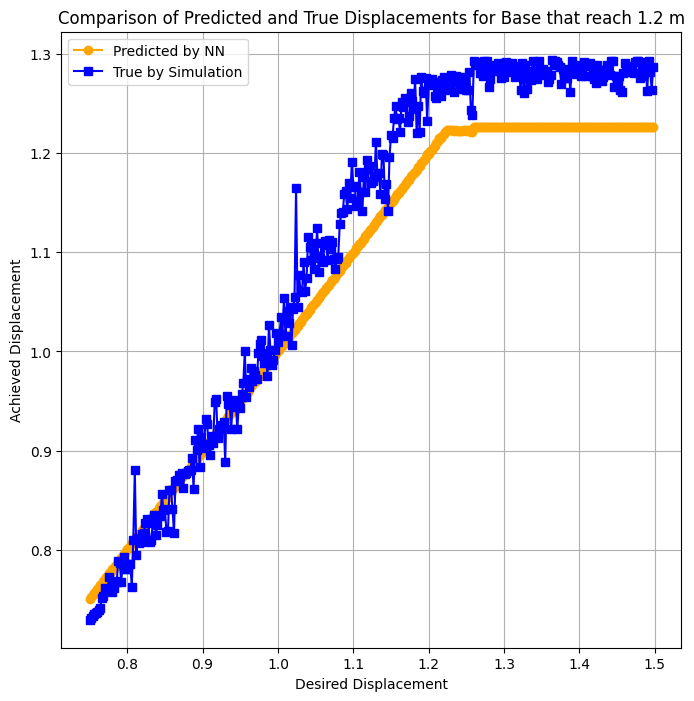

In [108]:
# COMPARISON

plt.figure(figsize=(8,8))
plt.plot(target_vec, Y_pred_vec, '-o', label='Predicted by NN', color='orange')
plt.plot(target_vec, Y_true_vec, '-s', label='True by Simulation', color='blue')
plt.xlabel('Desired Displacement')
plt.ylabel('Achieved Displacement')
plt.title('Comparison of Predicted and True Displacements for Base that reach 1.2 m')
plt.legend()
plt.grid(True)
plt.show()

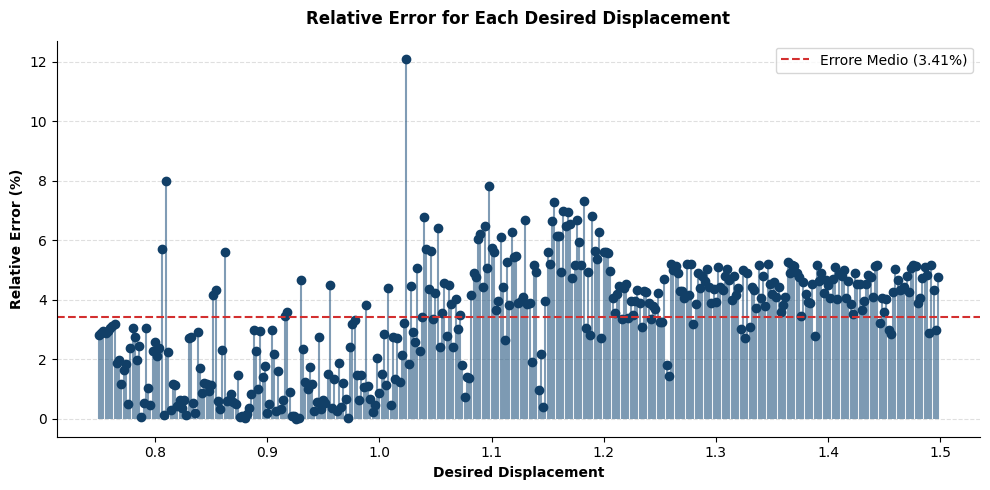

In [100]:
import matplotlib.pyplot as plt
import numpy as np

# Calcolo errore
Y_true = np.array(Y_true_vec)
Y_pred = np.array(Y_pred_vec)
target = np.array(target_vec)
error_vec = np.abs(Y_pred - Y_true) / np.maximum(np.abs(Y_true), 1e-12) * 100

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

# Aste e pallini (Lollipop)
ax.vlines(
    x=target, ymin=0, ymax=error_vec, color="#2B5B84", alpha=0.6, linewidth=1.5
)
ax.plot(target, error_vec, "o", color="#113F67", markersize=6)

# Linea errore medio
mean_err = np.mean(error_vec)
ax.axhline(
    y=mean_err,
    color="#D32F2F",
    linestyle="--",
    label=f"Errore Medio ({mean_err:.2f}%)",
)

ax.set_xlabel("Desired Displacement", fontweight="bold")
ax.set_ylabel("Relative Error (%)", fontweight="bold")
ax.set_title(
    "Relative Error for Each Desired Displacement", fontweight="bold", pad=12
)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

In [102]:
# DIFFERENT BASES 

# BASE FROM BRUTEFORCE SEARCH
Mb_sb =  10 
hb_sb = 0.1
Kb_sb = 4889.12

p_base_test_sb = {'Mb': Mb_sb, 'hb': hb_sb, 'Kb': Kb_sb}


Y_pred_vec_sb = []
Param_vec_sb = []

for i in range(len(target_vec)):
    desired_target = target_vec[i]
    params_trovati_sb, y_ottenuto_sb = find_robot_parameters(
    model, scaler_X, scaler_Y, p_base_test_sb, desired_target, lb, ub, param_names)

    Y_pred_vec_sb.append(y_ottenuto_sb)
    Param_vec_sb.append(params_trovati_sb)
       

In [103]:
print(np.array(Y_pred_vec_sb).shape)
print(np.array(Param_vec_sb).shape)

(375,)
(375, 9)


In [104]:
# COMPUTE THE OUTPUTS FOR THE FOUND PARAMETERS FOR FOLLOWING COMPARISON

Y_true_vec_sb = []
for i in range(np.array(Param_vec_sb).shape[0]):
    max_disp_sb, _, _, _ = simulate_peak_joint_position(Param_vec_sb[i])
    Y_true_vec_sb.append(max_disp_sb)

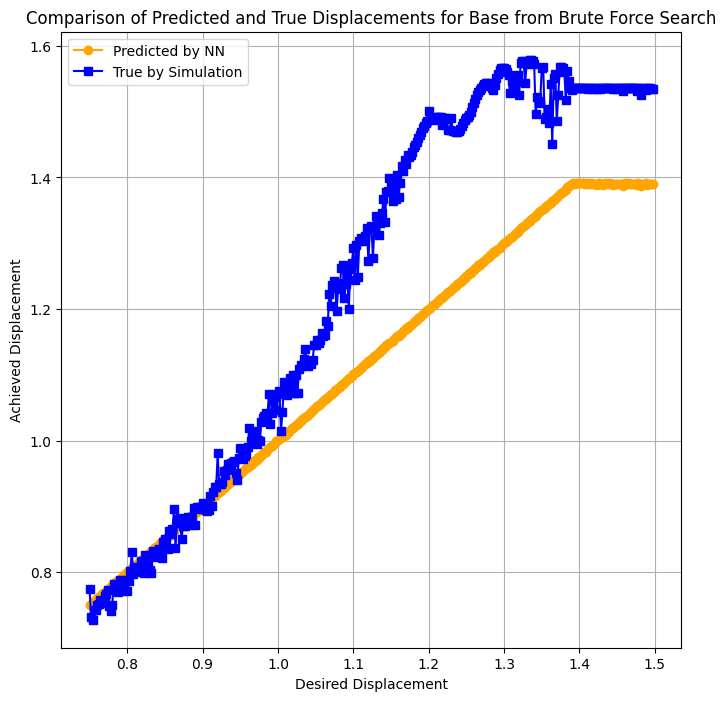

In [107]:
# COMPARISON

plt.figure(figsize=(8,8))
plt.plot(target_vec, Y_pred_vec_sb, '-o', label='Predicted by NN', color='orange')
plt.plot(target_vec, Y_true_vec_sb, '-s', label='True by Simulation', color='blue')
plt.xlabel('Desired Displacement')
plt.ylabel('Achieved Displacement')
plt.title('Comparison of Predicted and True Displacements for Base from Brute Force Search')
plt.legend()
plt.grid(True)
plt.show()

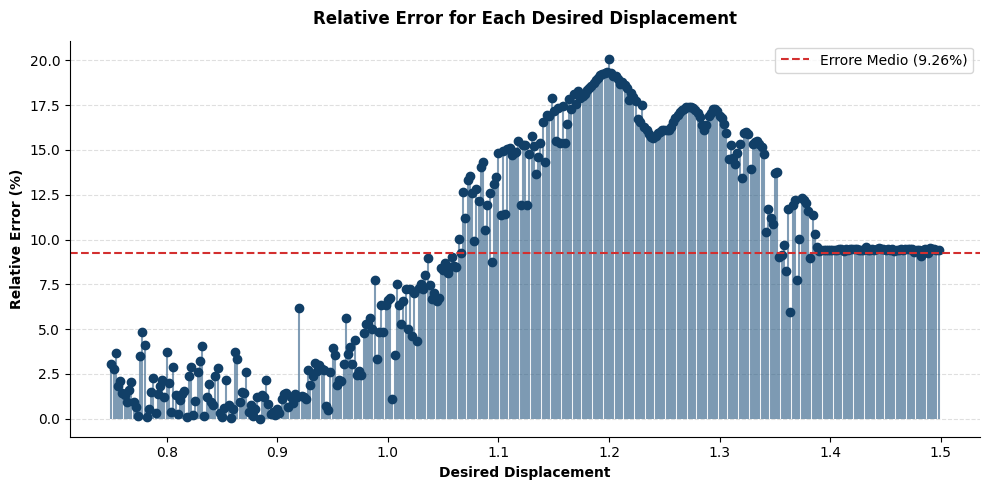

In [106]:
# Calcolo errore
Y_true = np.array(Y_true_vec_sb)
Y_pred = np.array(Y_pred_vec_sb)
target = np.array(target_vec)
error_vec = np.abs(Y_pred - Y_true) / np.maximum(np.abs(Y_true), 1e-12) * 100

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

# Aste e pallini (Lollipop)
ax.vlines(
    x=target, ymin=0, ymax=error_vec, color="#2B5B84", alpha=0.6, linewidth=1.5
)
ax.plot(target, error_vec, "o", color="#113F67", markersize=6)

# Linea errore medio
mean_err = np.mean(error_vec)
ax.axhline(
    y=mean_err,
    color="#D32F2F",
    linestyle="--",
    label=f"Errore Medio ({mean_err:.2f}%)",
)

ax.set_xlabel("Desired Displacement", fontweight="bold")
ax.set_ylabel("Relative Error (%)", fontweight="bold")
ax.set_title(
    "Relative Error for Each Desired Displacement", fontweight="bold", pad=12
)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()